# BNET SDF, Single-DAC, and Digital Capture Feature Test

This notebook targets the new BNET hardware build with:

- DDR input mode, stream 0 samples and stream 1 static weights
- `BNET:PIPELINE 1`, which selects the compiled static SDF/static pipeline hardware path
- `BNET:DAC:SINGLE 1`, so BNET scalar results are serialized onto OUT1 while OUT2 is driven to zero
- optional `BNET:DAC:SPLIT 1`, which emits each raw 14-bit result as high-7 then low-7 fields aligned to DAC bits `[13:7]`
- optional `ACQ:BIT:COMBINE 1`, which reconstructs one 14-bit IN1 acquisition word from ADC bits `[13:7]` of two neighboring RF samples; use acquisition decimation 2
- digital BNET output capture through `BNET:CAPTURE:COUNT?`, `BNET:CAPTURE:STATUS?`, and indexed `BNET:CAPTURE0:DATA?`-style reads

The main correctness check does not rely on analog loopback. It reads the captured digital BNET scalar stream from FPGA RAM and compares it directly with the software fixed-point reference.

In [79]:
from __future__ import annotations

import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

NOTEBOOK_DIR = Path.cwd()
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import redpitaya_scpi as scpi

RP_IP = "169.254.77.151"
RP_PORT = 5000
TIMEOUT_S = 20

SERIAL_VECTOR_LEN = 2048
SDF_VECTOR_LEN = 4096
VECTOR_LEN = SDF_VECTOR_LEN
UPLOAD_CHUNK_BYTES = 1024
ADC_CLK_HZ = 125_000_000

# Keep this modest so optional analog observation does not clip the ADC inputs.
TEST_AMPLITUDE_SCALE = 0.25
INPUT_PRE_PAD = 100
INPUT_POST_PAD = 100
PLOT_SAMPLES = 4096
BNET_DAC_SPLIT_OUTPUT = False  # True: each 14-bit BNET result becomes high7, low7 on OUT1.
ACQ_BIT_COMBINE = False  # True: reconstruct split RF samples on IN1; IN2 stays raw.

# Fast status checks avoid per-sample CAPTURE:DATA reads, so they are useful first-pass diagnostics.
RUN_SAFE_REGISTER_TESTS = True
RUN_ANALOG_LOOPBACK_DRAIN_TEST = True

# Full exact readback uses the rebuilt capture-data SCPI commands.
RUN_EXACT_DIGITAL_CAPTURE = True

ANALOG_CAPTURE_SAMPLES = 16384
ANALOG_READ_SAMPLES = 16384  # Split mode emits 8192 DAC samples; keep pre/post margin.
ACQ_PRE_TRIGGER_SAMPLES = 512
# Combined IN1 words are held for two ADC clocks, so combine mode requires decimation 2.
# Without combining, decimation 1 preserves the physical BNET waveform.
ACQ_DECIMATION = 2 if ACQ_BIT_COMBINE else 1
ACQ_DATA_UNITS = "RAW" if ACQ_BIT_COMBINE else "VOLTS"
ACQ_TRIGGER_SOURCE = "CH1_PE"  # Use "NOW" for immediate trigger, or e.g. "CH1_PE"/"CH1_NE".
ACQ_TRIGGER_DELAY_SAMPLES = 8092 - 100
ACQ_TRIGGER_LEVEL = 0.005
ACQ_TRIGGER_WAIT_TIMEOUT_S = 3.0
ACQ_TRIGGER_FILL_TIMEOUT_S = 3.0
ACQ_ARM_SETTLE_S = 0.05
ACQ_READ_MODE = "TRIG"  # "TRIG" keeps the returned buffer aligned to the trigger; "LATEST" reads newest samples.
ANALOG_DECIMATION = ACQ_DECIMATION
ANALOG_TAIL_GUARD_SAMPLES = 512
ANALOG_DRAIN_RMS_RATIO_LIMIT = 0.10
ANALOG_OUT2_RMS_RATIO_LIMIT = 0.10
ANALOG_MIN_ACTIVE_RMS_V = 0.01
ANALOG_MIN_ACTIVE_TO_IDLE_RATIO = 5.0
print(f"Target: {RP_IP}:{RP_PORT}")
print(f"SERIAL_VECTOR_LEN={SERIAL_VECTOR_LEN}, SDF_VECTOR_LEN={SDF_VECTOR_LEN}")

Target: 169.254.77.151:5000
SERIAL_VECTOR_LEN=2048, SDF_VECTOR_LEN=4096


## Connect and SCPI Helpers

In [80]:
rp = scpi.scpi(RP_IP, timeout=TIMEOUT_S, port=RP_PORT)
VERBOSE_SCPI = True

def cmd(command: str) -> None:
    if VERBOSE_SCPI:
        print(f">> {command}")
    rp.tx_txt(command)

def query(command: str) -> str:
    if VERBOSE_SCPI:
        print(f">> {command}")
    value = rp.txrx_txt(command).strip()
    if VERBOSE_SCPI:
        print(f"<< {value}")
    return value

def query_int(command: str) -> int:
    return int(query(command), 0)

def strict_cmd(command: str, delay_s: float = 0.01) -> None:
    cmd(command)
    time.sleep(delay_s)

def wait_for_bnet_done(timeout_s: float = 30.0) -> int:
    deadline = time.time() + timeout_s
    last_status = 0
    while time.time() < deadline:
        last_status = query_int("BNET:STATUS?")
        if last_status & 0x2:
            return last_status
        time.sleep(0.05)
    raise TimeoutError(f"BNET did not finish; last STATUS=0x{last_status:x}")

def timing_label(index: int) -> str:
    return ["total", "weight_load", "input_load", "output", "input_load_detail", "latency"][index]

def snapshot(label: str) -> dict[str, int]:
    data = {
        "status": query_int("BNET:STATUS?"),
        "config": query_int("BNET:CONFIG?"),
        "error": query_int("BNET:ERROR?"),
        "capture_count": query_int("BNET:CAPTURE:COUNT?"),
        "capture_status": query_int("BNET:CAPTURE:STATUS?"),
        "stream0_status": query_int("BNET:STREAM0:STATUS?"),
        "stream1_status": query_int("BNET:STREAM1:STATUS?"),
        "stream0_rptr": query_int("BNET:STREAM0:RPTR?"),
        "stream1_rptr": query_int("BNET:STREAM1:RPTR?"),
    }
    for i in range(6):
        data[f"time{i}_{timing_label(i)}"] = query_int(f"BNET:TIME{i}?")
    data["time_total"] = data["time0_total"]
    data["time_weight_load"] = data["time1_weight_load"]
    data["time_input_load"] = data["time2_input_load"]
    data["time_output"] = data["time3_output"]
    data["time_latency"] = data["time5_latency"]

    print(label)
    for key, value in data.items():
        print(f"  {key:24s} = {value} (0x{value:x})")
    return data

def cycles_to_us(cycles: int) -> float:
    return 1e6 * cycles / ADC_CLK_HZ

def warn_check(condition: bool, label: str, detail=None) -> bool:
    if condition:
        print(f"OK: {label}")
    else:
        print(f"WARNING: {label}")
        if detail is not None:
            print("  ", detail)
    return bool(condition)

def require_check(condition: bool, label: str, detail=None) -> None:
    if warn_check(condition, label, detail):
        return
    raise RuntimeError(f"Required BNET setup check failed: {label}; detail={detail}")

strict_cmd("*CLS")
print(query("*IDN?"))
print("Connected")

>> *CLS
>> *IDN?
<< REDPITAYA,INSTR2025,,01-21
REDPITAYA,INSTR2025,,01-21
Connected


## Command Smoke Test

This checks that the SCPI server and API were rebuilt with the new capture commands. If this cell fails with an unknown command or compile-era missing symbol, rebuild/install `rp-api` first, then rebuild/install `scpi-server`.

In [81]:
def scpi_error_queue(label: str) -> str:
    err = query("SYSTem:ERRor:NEXT?")
    print(f"SCPI error after {label}: {err}")
    return err

strict_cmd("BNET:RST")
scpi_error_queue("BNET:RST")
strict_cmd("BNET:CH0:DATA 12345")
scpi_error_queue("BNET:CH0:DATA 12345")
ch0_readback = query_int("BNET:CH0:DATA?")
warn_check(ch0_readback == 12345, "BNET CH0 register write/read works", ch0_readback)

strict_cmd("BNET:MODE DDR")
scpi_error_queue("BNET:MODE DDR")
warn_check(query("BNET:MODE?") == "DDR", "BNET mode is DDR")

strict_cmd("BNET:PIPELINE 1")
scpi_error_queue("BNET:PIPELINE 1")
strict_cmd("BNET:DAC:SINGLE 1")
scpi_error_queue("BNET:DAC:SINGLE 1")
strict_cmd(f"BNET:DAC:SPLIT {int(BNET_DAC_SPLIT_OUTPUT)}")
scpi_error_queue("BNET:DAC:SPLIT")
strict_cmd(f"ACQ:BIT:COMBINE {int(ACQ_BIT_COMBINE)}")
scpi_error_queue("ACQ:BIT:COMBINE")
strict_cmd("BNET:WEIGHT:REUSE 0")
scpi_error_queue("BNET:WEIGHT:REUSE 0")
warn_check(query_int("BNET:PIPELINE?") == 1, "BNET pipeline/static path enabled")
warn_check(query_int("BNET:DAC:SINGLE?") == 1, "BNET single-DAC output enabled")
warn_check(query_int("BNET:DAC:SPLIT?") == int(BNET_DAC_SPLIT_OUTPUT), "BNET split-DAC output state matches request")
warn_check(query_int("ACQ:BIT:COMBINE?") == int(ACQ_BIT_COMBINE), "IN1 acquisition bit-combine state matches request")
warn_check(not ACQ_BIT_COMBINE or BNET_DAC_SPLIT_OUTPUT, "IN1 combine mode is paired with split-DAC output")
expected_config = 0x62 | (0x80 if BNET_DAC_SPLIT_OUTPUT else 0) | (0x100 if ACQ_BIT_COMBINE else 0)
warn_check(query_int("BNET:CONFIG?") == expected_config, f"BNET config is expected 0x{expected_config:02x}")

count = query_int("BNET:CAPTURE:COUNT?")
status = query_int("BNET:CAPTURE:STATUS?")
print(f"Initial capture count={count}, status=0x{status:x}")
print("New BNET command smoke test completed")

>> BNET:RST
>> SYSTem:ERRor:NEXT?
<< 0,"No error"
SCPI error after BNET:RST: 0,"No error"
>> BNET:CH0:DATA 12345
>> SYSTem:ERRor:NEXT?
<< 0,"No error"
SCPI error after BNET:CH0:DATA 12345: 0,"No error"
>> BNET:CH0:DATA?
<< 12345
OK: BNET CH0 register write/read works
>> BNET:MODE DDR
>> SYSTem:ERRor:NEXT?
<< 0,"No error"
SCPI error after BNET:MODE DDR: 0,"No error"
>> BNET:MODE?
<< DDR
OK: BNET mode is DDR
>> BNET:PIPELINE 1
>> SYSTem:ERRor:NEXT?
<< 0,"No error"
SCPI error after BNET:PIPELINE 1: 0,"No error"
>> BNET:DAC:SINGLE 1
>> SYSTem:ERRor:NEXT?
<< 0,"No error"
SCPI error after BNET:DAC:SINGLE 1: 0,"No error"
>> BNET:WEIGHT:REUSE 0
>> SYSTem:ERRor:NEXT?
<< 0,"No error"
SCPI error after BNET:WEIGHT:REUSE 0: 0,"No error"
>> BNET:PIPELINE?
<< 1
OK: BNET pipeline/static path enabled
>> BNET:DAC:SINGLE?
<< 1
OK: BNET single-DAC output enabled
>> BNET:CONFIG?
<< 98
OK: BNET config is expected 0x62
>> BNET:CAPTURE:COUNT?
<< 0
>> BNET:CAPTURE:STATUS?
<< 0
Initial capture count=0, status=0

## Newest SCPI/API Capture-Data Smoke Test

The rebuilt server should expose all supported capture read forms: `BNET:CAPTURE0:DATA?`, `BNET:CAPTURE:DATA0?`, and `BNET:CAPTURE:DATA? 0`. Before any BNET run, index 0 may be out of range if the capture count is zero, so this cell only performs reads when data is already present.

In [82]:
def smoke_test_indexed_capture_data_command() -> None:
    count = query_int("BNET:CAPTURE:COUNT?")
    print(f"Current capture count: {count}")
    if count > 0:
        values = {
            "BNET:CAPTURE0:DATA?": query_int("BNET:CAPTURE0:DATA?"),
            "BNET:CAPTURE:DATA0?": query_int("BNET:CAPTURE:DATA0?"),
            "BNET:CAPTURE:DATA? 0": query_int("BNET:CAPTURE:DATA? 0"),
        }
        print(values)
        warn_check(len(set(values.values())) == 1, "Indexed capture-data command forms agree", values)
    else:
        print("No capture samples yet; indexed capture-data read will be exercised by the full tests below.")

smoke_test_indexed_capture_data_command()

>> BNET:CAPTURE:COUNT?
<< 0
Current capture count: 0
No capture samples yet; indexed capture-data read will be exercised by the full tests below.


## Fixed-Point Reference Model

The HDL uses signed 14-bit samples and packed 7-bit signed weights. The helper below mirrors the per-stage butterfly addressing and the HDL rounding/saturation rule.

In [83]:
def clip_i14(values: np.ndarray) -> np.ndarray:
    return np.clip(np.rint(values), -8192, 8191).astype(np.int16)

def pack_weight_word(y0_weight: int, y1_weight: int) -> np.int16:
    high = int(y0_weight) & 0x7f
    low = int(y1_weight) & 0x7f
    packed_u14 = (high << 7) | low
    return np.int16(packed_u14 if packed_u14 < 0x2000 else packed_u14 - 0x4000)

def unpack_s7(value: int) -> int:
    value &= 0x7f
    return value - 0x80 if value & 0x40 else value

def make_test_input(vector_len: int, sign: int = 1, phase: float = 0.0) -> np.ndarray:
    active_len = vector_len - INPUT_PRE_PAD - INPUT_POST_PAD
    if active_len <= 0:
        raise ValueError("Padding is longer than the vector")
    values = np.zeros(vector_len, dtype=np.int16)
    n = np.arange(active_len)
    active = sign * TEST_AMPLITUDE_SCALE * (
        2500 +
        1800 * np.sin(2 * np.pi * (n + phase) / 97.0) +
        700 * np.sin(2 * np.pi * (n + phase) / 31.0)
    )
    values[INPUT_PRE_PAD:INPUT_PRE_PAD + active_len] = clip_i14(active)
    return values

def make_near_identity_weights(vector_len: int) -> np.ndarray:
    stage_count = int(np.log2(vector_len))
    weights = np.zeros(vector_len * stage_count, dtype=np.int16)
    one = 63
    zero = 0
    for stage in range(stage_count):
        half_span = 1 << stage
        base = stage * vector_len
        for pair in range(vector_len // 2):
            pair_in_group = pair & (half_span - 1)
            group_base = (pair - pair_in_group) << 1
            addr_a = group_base + pair_in_group
            addr_b = addr_a + half_span
            weights[base + addr_a] = pack_weight_word(one, zero)
            weights[base + addr_b] = pack_weight_word(zero, one)
    return weights

def butterfly_reference_i14(samples_i14: np.ndarray, packed_weights: np.ndarray) -> np.ndarray:
    data = np.asarray(samples_i14, dtype=np.int64).copy()
    vector_len = data.size
    stage_count = int(np.log2(vector_len))
    packed = np.asarray(packed_weights, dtype=np.int16).astype(np.int64)
    assert packed.size == vector_len * stage_count
    for stage in range(stage_count):
        half_span = 1 << stage
        old = data.copy()
        base = stage * vector_len
        for pair in range(vector_len // 2):
            pair_in_group = pair & (half_span - 1)
            group_base = (pair - pair_in_group) << 1
            addr_a = group_base + pair_in_group
            addr_b = addr_a + half_span
            wa = int(packed[base + addr_a]) & 0x3fff
            wb = int(packed[base + addr_b]) & 0x3fff
            y0 = old[addr_a] * unpack_s7(wa >> 7) + old[addr_b] * unpack_s7(wb >> 7)
            y1 = old[addr_a] * unpack_s7(wa) + old[addr_b] * unpack_s7(wb)
            data[addr_a] = np.clip((y0 + 32) >> 6, -8192, 8191)
            data[addr_b] = np.clip((y1 + 32) >> 6, -8192, 8191)
    return data.astype(np.int16)

def butterfly_sdf_stream_reference_i14(samples_i14: np.ndarray, packed_weights: np.ndarray) -> np.ndarray:
    data = np.asarray(samples_i14, dtype=np.int64).copy()
    vector_len = data.size
    stage_count = int(np.log2(vector_len))
    packed = np.asarray(packed_weights, dtype=np.int16).astype(np.int64)
    assert packed.size == vector_len * stage_count

    for stage in range(stage_count):
        delay_len = 1 << stage
        x_delay = np.zeros(delay_len, dtype=np.int64)
        y1_delay = np.zeros(delay_len, dtype=np.int64)
        out = []
        base = stage * vector_len

        for sample_idx, sample in enumerate(data):
            delay_addr = sample_idx & (delay_len - 1)
            second_half = bool(sample_idx & delay_len)
            group_base = (sample_idx >> (stage + 1)) << (stage + 1)
            addr_a = group_base + delay_addr
            addr_b = addr_a + delay_len

            if second_half:
                wa = int(packed[base + addr_a]) & 0x3fff
                wb = int(packed[base + addr_b]) & 0x3fff
                y0 = x_delay[delay_addr] * unpack_s7(wa >> 7) + sample * unpack_s7(wb >> 7)
                y1 = x_delay[delay_addr] * unpack_s7(wa) + sample * unpack_s7(wb)
                out.append(int(np.clip((y0 + 32) >> 6, -8192, 8191)))
                y1_delay[delay_addr] = int(np.clip((y1 + 32) >> 6, -8192, 8191))
            else:
                if sample_idx >= 2 * delay_len:
                    out.append(int(y1_delay[delay_addr]))
                x_delay[delay_addr] = sample

        out.extend(int(v) for v in y1_delay)
        data = np.asarray(out, dtype=np.int64)
        assert data.size == vector_len, (stage, data.size, vector_len)

    return data.astype(np.int16)

def pack_i16_le(values: np.ndarray) -> bytes:
    return np.asarray(values, dtype="<i2").tobytes()

def payload_sizes(vector_len: int) -> tuple[int, int, int, int]:
    stage_count = int(np.log2(vector_len))
    sample_bytes = vector_len * 2
    weight_words = vector_len * stage_count
    weight_bytes = weight_words * 2
    return stage_count, sample_bytes, weight_words, weight_bytes

sdf_input = make_test_input(SDF_VECTOR_LEN)
sdf_weights = make_near_identity_weights(SDF_VECTOR_LEN)
sdf_frame_reference = butterfly_reference_i14(sdf_input, sdf_weights).astype(np.int32)
sdf_reference = butterfly_sdf_stream_reference_i14(sdf_input, sdf_weights).astype(np.int32)

warm_input = make_test_input(SDF_VECTOR_LEN, sign=-1, phase=19.0)
warm_frame_reference = butterfly_reference_i14(warm_input, sdf_weights).astype(np.int32)
warm_reference = butterfly_sdf_stream_reference_i14(warm_input, sdf_weights).astype(np.int32)

print(f"Input range: {sdf_input.min()} .. {sdf_input.max()} codes")
print(f"SDF stream reference range: {sdf_reference.min()} .. {sdf_reference.max()} codes")
ref_delta = sdf_reference.astype(np.int64) - sdf_frame_reference.astype(np.int64)
print(f"SDF stream ref vs frame ref: mismatches={np.count_nonzero(ref_delta)}, max_abs={np.max(np.abs(ref_delta)) if ref_delta.size else 0}")
print(f"Weight words: {sdf_weights.size}")

Input range: 0 .. 1250 codes
SDF stream reference range: 0 .. 1035 codes
SDF stream ref vs frame ref: mismatches=0, max_abs=0
Weight words: 49152


## DDR Upload Helpers

In [84]:
def align_up(value: int, alignment: int) -> int:
    return (value + alignment - 1) & ~(alignment - 1)

def release_slot(slot: int) -> None:
    try:
        strict_cmd(f"BNET:DDR:SLOT{slot}:RELEASE")
    except Exception as exc:
        print(f"Ignoring slot {slot} release failure: {exc}")

def reserve_bnet_slot(slot: int, address: int, size_bytes: int) -> None:
    strict_cmd(f"BNET:DDR:SLOT{slot}:RESERVE {address},{size_bytes}")

def upload_bnet_slot_bytes(slot: int, offset_bytes: int, data: bytes) -> None:
    old_verbose = globals().get("VERBOSE_SCPI", True)
    globals()["VERBOSE_SCPI"] = False
    try:
        for chunk_offset in range(0, len(data), UPLOAD_CHUNK_BYTES):
            chunk = data[chunk_offset:chunk_offset + UPLOAD_CHUNK_BYTES]
            payload = ",".join(str(b) for b in chunk)
            strict_cmd(f"BNET:DDR:SLOT{slot}:OFFSET{offset_bytes + chunk_offset}:DATA{len(chunk)} {payload}")
    finally:
        globals()["VERBOSE_SCPI"] = old_verbose

def attach_slot_to_stream(slot: int, stream: int, buffer: int = 0) -> None:
    strict_cmd(f"BNET:DDR:SLOT{slot}:STREAM{stream}:BUF{buffer}")

def prepare_ddr_buffers(input_i16: np.ndarray, weight_i16: np.ndarray | None = None) -> tuple[int, int | None]:
    ddr_start = query_int("BNET:DDR:START?")
    ddr_size = query_int("BNET:DDR:SIZE?")
    sample_data = pack_i16_le(input_i16)
    sample_addr = align_up(ddr_start, 0x1000)

    release_slot(0)
    if weight_i16 is not None:
        release_slot(1)
    reserve_bnet_slot(0, sample_addr, len(sample_data))
    upload_bnet_slot_bytes(0, 0, sample_data)
    attach_slot_to_stream(0, stream=0, buffer=0)
    stream0_base = query_int("BNET:STREAM0:BASE0?")
    stream0_length = query_int("BNET:STREAM0:LENGTH?")
    require_check(stream0_base == sample_addr, "STREAM0 BASE0 matches sample slot", {"read": stream0_base, "expected": sample_addr})
    require_check(stream0_length == len(sample_data), "STREAM0 length matches sample bytes", {"read": stream0_length, "expected": len(sample_data)})

    if weight_i16 is None:
        return sample_addr, None

    weight_data = pack_i16_le(weight_i16)
    weight_addr = align_up(sample_addr + len(sample_data), 0x1000)
    required_end = weight_addr + len(weight_data)
    if required_end > ddr_start + ddr_size:
        raise RuntimeError("BNET DDR test buffers do not fit in reported DDR region")

    reserve_bnet_slot(1, weight_addr, len(weight_data))
    upload_bnet_slot_bytes(1, 0, weight_data)
    attach_slot_to_stream(1, stream=1, buffer=0)
    stream1_base = query_int("BNET:STREAM1:BASE0?")
    stream1_length = query_int("BNET:STREAM1:LENGTH?")
    require_check(stream1_base == weight_addr, "STREAM1 BASE0 matches weight slot", {"read": stream1_base, "expected": weight_addr})
    require_check(stream1_length == len(weight_data), "STREAM1 length matches weight bytes", {"read": stream1_length, "expected": len(weight_data)})
    return sample_addr, weight_addr

## Digital Capture Helpers

In [85]:
def parse_int_scpi_array(text: str) -> np.ndarray:
    stripped = text.strip().strip("{}")
    if not stripped:
        return np.array([], dtype=np.int32)
    return np.array([int(item, 0) for item in stripped.split(",") if item.strip()], dtype=np.int32)

def read_bnet_capture_block(start: int, samples: int) -> np.ndarray:
    old_verbose = globals().get("VERBOSE_SCPI", True)
    globals()["VERBOSE_SCPI"] = False
    try:
        rp.tx_txt(f"BNET:CAPTURE:DATA:START:N? {int(start)},{int(samples)}")
        text = rp.rx_txt()
    finally:
        globals()["VERBOSE_SCPI"] = old_verbose
    return parse_int_scpi_array(text)

def read_bnet_capture(max_samples: int | None = None) -> tuple[np.ndarray, dict[str, int]]:
    count = query_int("BNET:CAPTURE:COUNT?")
    status = query_int("BNET:CAPTURE:STATUS?")
    read_count = count if max_samples is None else min(count, int(max_samples))
    t0 = time.time()
    try:
        data = read_bnet_capture_block(0, read_count)
        if data.size != read_count:
            raise RuntimeError(f"bulk read returned {data.size} samples, expected {read_count}")
        elapsed_s = time.time() - t0
        print(f"Digital capture bulk readback: {read_count} samples in {elapsed_s:.2f} s")
        return data.astype(np.int32), {"count": int(count), "status": int(status), "read_seconds": float(elapsed_s), "read_mode": "bulk"}
    except Exception as exc:
        print(f"Bulk capture read failed ({exc}); falling back to indexed reads")

    data = np.empty(read_count, dtype=np.int32)
    old_verbose = globals().get("VERBOSE_SCPI", True)
    try:
        for idx in range(read_count):
            globals()["VERBOSE_SCPI"] = idx < 4 or idx == read_count - 1 or (idx % 512 == 0)
            data[idx] = query_int(f"BNET:CAPTURE:DATA? {idx}")
    finally:
        globals()["VERBOSE_SCPI"] = old_verbose
    elapsed_s = time.time() - t0
    print(f"Digital capture readback: {read_count} scalar queries in {elapsed_s:.2f} s ({elapsed_s / max(read_count, 1):.4f} s/query)")
    return data, {"count": int(count), "status": int(status), "read_seconds": float(elapsed_s), "read_mode": "indexed"}

def normalized_correlation(a: np.ndarray, b: np.ndarray) -> float:
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    n = min(a.size, b.size)
    if n == 0:
        return 0.0
    a = a[:n] - np.mean(a[:n])
    b = b[:n] - np.mean(b[:n])
    denom = np.linalg.norm(a) * np.linalg.norm(b)
    return 0.0 if denom == 0 else float(np.dot(a, b) / denom)

def capture_metrics(captured: np.ndarray, expected: np.ndarray) -> dict[str, object]:
    scored_len = min(captured.size, expected.size)
    error = captured[:scored_len].astype(np.int64) - expected[:scored_len].astype(np.int64)
    mismatch_positions = np.flatnonzero(error)
    return {
        "scored_len": int(scored_len),
        "exact_match": bool(captured.size == expected.size and np.count_nonzero(error) == 0),
        "mismatch_count": int(np.count_nonzero(error)),
        "max_abs_error": int(np.max(np.abs(error))) if error.size else 0,
        "correlation": normalized_correlation(captured[:scored_len], expected[:scored_len]),
        "first_mismatch": int(mismatch_positions[0]) if mismatch_positions.size else None,
    }

def bit_reverse_indices(length: int) -> np.ndarray:
    bits = int(np.log2(length))
    idx = np.arange(length, dtype=np.uint32)
    rev = np.zeros(length, dtype=np.uint32)
    for bit in range(bits):
        rev = (rev << 1) | ((idx >> bit) & 1)
    return rev.astype(np.int64)

def best_circular_shift(captured: np.ndarray, expected: np.ndarray, max_abs_shift: int = 512) -> dict[str, object]:
    captured = np.asarray(captured, dtype=np.int64)
    expected = np.asarray(expected, dtype=np.int64)
    n = min(captured.size, expected.size)
    captured = captured[:n]
    expected = expected[:n]
    best = {"shift": 0, "mismatch_count": n + 1, "max_abs_error": None, "correlation": -2.0}
    for shift in range(-max_abs_shift, max_abs_shift + 1):
        shifted = np.roll(expected, shift)
        err = captured - shifted
        mismatch = int(np.count_nonzero(err))
        corr = normalized_correlation(captured, shifted)
        if (mismatch < best["mismatch_count"]) or (mismatch == best["mismatch_count"] and corr > best["correlation"]):
            best = {
                "shift": int(shift),
                "mismatch_count": mismatch,
                "max_abs_error": int(np.max(np.abs(err))) if err.size else 0,
                "correlation": corr,
            }
    return best

def shift_with_zero_fill(values: np.ndarray, shift: int) -> np.ndarray:
    values = np.asarray(values)
    shifted = np.zeros_like(values)
    if shift > 0:
        shifted[shift:] = values[:-shift]
    elif shift < 0:
        shifted[:shift] = values[-shift:]
    else:
        shifted[:] = values
    return shifted

def best_linear_shift(captured: np.ndarray, expected: np.ndarray, max_abs_shift: int = 64) -> dict[str, object]:
    captured = np.asarray(captured, dtype=np.int64)
    expected = np.asarray(expected, dtype=np.int64)
    n = min(captured.size, expected.size)
    captured = captured[:n]
    expected = expected[:n]
    best = {"shift": 0, "mismatch_count": n + 1, "max_abs_error": None, "correlation": -2.0, "first_large_error": None}
    for shift in range(-max_abs_shift, max_abs_shift + 1):
        shifted = shift_with_zero_fill(expected, shift)
        err = captured - shifted
        mismatch = int(np.count_nonzero(err))
        corr = normalized_correlation(captured, shifted)
        large = np.flatnonzero(np.abs(err) > 8)
        if (corr > best["correlation"]) or (corr == best["correlation"] and mismatch < best["mismatch_count"]):
            best = {
                "shift": int(shift),
                "mismatch_count": mismatch,
                "max_abs_error": int(np.max(np.abs(err))) if err.size else 0,
                "correlation": corr,
                "first_large_error": int(large[0]) if large.size else None,
            }
    return best

def spike_report(captured: np.ndarray, expected: np.ndarray, threshold: int = 128, max_rows: int = 16) -> list[tuple[int, int, int, int]]:
    n = min(captured.size, expected.size)
    err = captured[:n].astype(np.int64) - expected[:n].astype(np.int64)
    idxs = np.flatnonzero(np.abs(err) >= threshold)
    return [(int(i), int(captured[i]), int(expected[i]), int(err[i])) for i in idxs[:max_rows]]

def print_capture_diagnostics(captured: np.ndarray, expected: np.ndarray, input_i16: np.ndarray) -> None:
    probes = [0, 1, 2, 3, 10, 100, 255, 512, 1024, 2048, 3072, captured.size - 1]
    print("Probe samples: idx, captured, expected, input")
    for idx in probes:
        if 0 <= idx < captured.size:
            print(f"  {idx:5d}: {int(captured[idx]):7d} {int(expected[idx]):7d} {int(input_i16[idx]):7d}")

    raw_input_metrics = capture_metrics(captured, np.asarray(input_i16, dtype=np.int32))
    bitrev_expected = expected[bit_reverse_indices(expected.size)]
    bitrev_metrics = capture_metrics(captured, bitrev_expected)
    shift_metrics = best_circular_shift(captured, expected)
    linear_shift_metrics = best_linear_shift(captured, expected)
    aligned_expected = shift_with_zero_fill(expected, linear_shift_metrics["shift"])
    aligned_spikes = spike_report(captured, aligned_expected)

    print("Alternative comparisons")
    print(f"  captured vs raw input         : {raw_input_metrics}")
    print(f"  captured vs bit-reversed ref  : {bitrev_metrics}")
    print(f"  best circular shift of ref    : {shift_metrics}")
    print(f"  best zero-fill shift of ref   : {linear_shift_metrics}")
    if aligned_spikes:
        print("  first aligned spike/errors >=128 codes: idx, captured, shifted_expected, error")
        for row in aligned_spikes:
            print(f"    {row[0]:5d}: {row[1]:7d} {row[2]:7d} {row[3]:7d}")

def plot_capture(captured: np.ndarray, expected: np.ndarray, title: str) -> None:
    n = min(max(captured.size, expected.size), PLOT_SAMPLES)
    x = np.arange(n)
    expected_plot = np.full(n, np.nan, dtype=float)
    captured_plot = np.full(n, np.nan, dtype=float)
    expected_plot[:min(expected.size, n)] = expected[:min(expected.size, n)]
    captured_plot[:min(captured.size, n)] = captured[:min(captured.size, n)]
    fig, axes = plt.subplots(3, 1, figsize=(14, 8), constrained_layout=True)
    axes[0].plot(x, expected_plot, label=f"expected ({expected.size})", linewidth=1.4)
    axes[0].plot(x, captured_plot, label=f"captured ({captured.size})", alpha=0.75)
    axes[0].set_title(title)
    axes[0].set_ylabel("signed code")
    axes[0].grid(True)
    axes[0].legend()

    common_n = min(captured.size, expected.size, n)
    axes[1].plot(np.arange(common_n), captured[:common_n] - expected[:common_n], label="captured - expected")
    axes[1].set_title("First-window integer error")
    axes[1].set_ylabel("codes")
    axes[1].grid(True)
    axes[1].legend()

    full_n = min(captured.size, expected.size)
    axes[2].plot(np.arange(full_n), captured[:full_n] - expected[:full_n], linewidth=0.9)
    axes[2].set_title("Full-vector integer error")
    axes[2].set_xlabel("serialized scalar index")
    axes[2].set_ylabel("codes")
    axes[2].grid(True)
    plt.show()

## Run Helpers

`cold=True` uploads weights and resets BNET. `cold=False` keeps the already-loaded static weights and uploads only a new input frame, which is the important streaming-like reuse case.

In [86]:
def configure_sdf_run(input_i16: np.ndarray, weight_i16: np.ndarray | None, *, cold: bool) -> dict[str, int]:
    vector_len = int(input_i16.size)
    stage_count, sample_bytes, weight_words, weight_bytes = payload_sizes(vector_len)

    if cold:
        strict_cmd("BNET:RST")

    prepare_ddr_buffers(input_i16, weight_i16)
    strict_cmd(f"BNET:VLEN {vector_len}")
    strict_cmd("BNET:STREAM0:FORMAT 0")
    strict_cmd("BNET:STREAM1:FORMAT 0")
    strict_cmd("BNET:STREAM0:ENABLE 1")
    strict_cmd(f"BNET:STREAM1:ENABLE {1 if weight_i16 is not None else 0}")
    strict_cmd("BNET:STREAM0:COMMIT0")
    if weight_i16 is not None:
        strict_cmd("BNET:STREAM1:COMMIT0")
    strict_cmd("BNET:MODE DDR")
    strict_cmd("BNET:PIPELINE 1")
    strict_cmd("BNET:DAC:SINGLE 1")
    strict_cmd(f"BNET:DAC:SPLIT {int(BNET_DAC_SPLIT_OUTPUT)}")
    strict_cmd(f"ACQ:BIT:COMBINE {int(ACQ_BIT_COMBINE)}")
    strict_cmd("BNET:WEIGHT:REUSE 0")

    observed_config = query_int("BNET:CONFIG?")
    expected_config = 0x62 | (0x80 if BNET_DAC_SPLIT_OUTPUT else 0) | (0x100 if ACQ_BIT_COMBINE else 0)
    require_check(observed_config == expected_config, f"BNET config is expected 0x{expected_config:02x} before run", {"read": observed_config, "expected": expected_config})
    return {
        "vector_len": vector_len,
        "sample_bytes": sample_bytes,
        "weight_bytes": weight_bytes,
        "weight_uploaded": int(weight_i16 is not None),
    }

def run_sdf_capture_test(label: str, input_i16: np.ndarray, expected_i32: np.ndarray, *, cold: bool, weight_i16: np.ndarray | None) -> dict[str, object]:
    setup = configure_sdf_run(input_i16, weight_i16, cold=cold)
    before_stream1_rptr = query_int("BNET:STREAM1:RPTR?")
    strict_cmd("BNET:START")
    status = wait_for_bnet_done(timeout_s=30.0)
    print(f"{label} completed with STATUS=0x{status:x}")
    run = snapshot(label)

    capture_count_for_probes = int(run.get("capture_count", 0))
    print("Post-run capture-data smoke reads:")
    data0_forms = {
        "BNET:CAPTURE0:DATA?": query_int("BNET:CAPTURE0:DATA?"),
        "BNET:CAPTURE:DATA0?": query_int("BNET:CAPTURE:DATA0?"),
        "BNET:CAPTURE:DATA? 0": query_int("BNET:CAPTURE:DATA? 0"),
    }
    print("  DATA0 forms =", data0_forms)
    # assert len(set(data0_forms.values())) == 1, data0_forms
    if capture_count_for_probes > 1:
        print("  DATA1 =", query_int("BNET:CAPTURE1:DATA?"))
    probe_candidates = (2, 3, 10, 255, setup["vector_len"] - 1)
    for probe_idx in probe_candidates:
        if 0 <= probe_idx < capture_count_for_probes:
            print(f"  DATA{probe_idx} param =", query_int(f"BNET:CAPTURE:DATA? {probe_idx}"))
        else:
            print(f"  DATA{probe_idx} param skipped; capture_count={capture_count_for_probes}")
    captured, capture_info = read_bnet_capture(max_samples=setup["vector_len"])
    metrics = capture_metrics(captured, expected_i32)

    print("Digital capture summary")
    print(f"  count              = {capture_info['count']}")
    print(f"  status             = 0x{capture_info['status']:x}")
    print(f"  expected samples   = {expected_i32.size}")
    print(f"  read samples       = {captured.size}")
    if capture_info["count"] != setup["vector_len"]:
        print(f"WARNING: digital capture is truncated: count={capture_info['count']}, expected={setup['vector_len']}")
    for key, value in metrics.items():
        print(f"  {key:18s} = {value}")

    if not metrics["exact_match"]:
        print_capture_diagnostics(captured, expected_i32, input_i16)
        aligned = best_linear_shift(captured, expected_i32)
        shifted_expected = shift_with_zero_fill(expected_i32, aligned["shift"])
        plot_capture(captured, shifted_expected, f"{label} - expected shifted by {aligned['shift']} samples")

    # assert run["error"] == 0, run
    # assert run["status"] & 0x2, run
    # assert run["stream0_rptr"] >= setup["sample_bytes"], run
    # if weight_i16 is not None:
        # assert run["stream1_rptr"] >= setup["weight_bytes"], run
    # else:
        # assert run["stream1_rptr"] == before_stream1_rptr, (before_stream1_rptr, run)
    plot_capture(captured, expected_i32, label)

    # assert capture_info["count"] == setup["vector_len"], capture_info
    # assert capture_info["status"] == 0, capture_info
    # assert metrics["exact_match"], metrics
    return {
        "label": label,
        "setup": setup,
        "run": run,
        "capture": capture_info,
        "metrics": metrics,
        "captured": captured,
        "expected": expected_i32,
    }

## Fast Status Feature Checks

These checks avoid `BNET:CAPTURE:DATA...` reads. They verify that the new hardware path runs, that the capture window is exactly one 4096-sample vector, that stream pointers are sane, and that the warm reused-weight path is much faster than the cold path.

In [87]:
def run_sdf_status_only_test(label: str, input_i16: np.ndarray, *, cold: bool, weight_i16: np.ndarray | None) -> dict[str, object]:
    setup = configure_sdf_run(input_i16, weight_i16, cold=cold)
    before_stream1_rptr = query_int("BNET:STREAM1:RPTR?")
    strict_cmd("BNET:START")
    status = wait_for_bnet_done(timeout_s=30.0)
    print(f"{label} completed with STATUS=0x{status:x}")
    run = snapshot(label)

    warn_check(bool(run["status"] & 0x2), f"{label}: BNET done bit set", run)
    warn_check(run["error"] == 0, f"{label}: no BNET stream error", run)
    warn_check(run["capture_count"] == setup["vector_len"], f"{label}: capture count equals vector length", run)
    warn_check(run["capture_status"] == 0, f"{label}: capture status is clean", run)
    warn_check(run["stream0_rptr"] >= setup["sample_bytes"], f"{label}: sample stream consumed expected bytes", run)
    if weight_i16 is not None:
        warn_check(run["stream1_rptr"] >= setup["weight_bytes"], f"{label}: weight stream consumed expected bytes", run)
    else:
        warn_check(run["stream1_rptr"] == before_stream1_rptr, f"{label}: weight stream pointer unchanged during reuse", (before_stream1_rptr, run))

    print(
        f"{label}: total={run['time_total']} cycles ({cycles_to_us(run['time_total']):.2f} us), "
        f"input={run['time_input_load']} cycles, output={run['time_output']} cycles, "
        f"latency={run['time_latency']} cycles"
    )
    return {"label": label, "setup": setup, "run": run}

if RUN_SAFE_REGISTER_TESTS:
    safe_cold_result = run_sdf_status_only_test(
        "SAFE cold static SDF 4096 status/counter test",
        sdf_input,
        cold=True,
        weight_i16=sdf_weights,
    )
    safe_warm_result = run_sdf_status_only_test(
        "SAFE warm static SDF 4096 status/counter test",
        warm_input,
        cold=False,
        weight_i16=None,
    )
    safe_speedup = safe_cold_result["run"]["time_total"] / safe_warm_result["run"]["time_total"]
    print(f"Warm-vs-cold total-cycle speedup: {safe_speedup:.2f}x")
else:
    safe_cold_result = safe_warm_result = {"skipped": True}
    print("Safe register tests skipped")

>> BNET:RST
>> BNET:DDR:START?
<< 16777216
>> BNET:DDR:SIZE?
<< 33554432
>> BNET:DDR:SLOT0:RELEASE
>> BNET:DDR:SLOT1:RELEASE
>> BNET:DDR:SLOT0:RESERVE 16777216,8192
>> BNET:DDR:SLOT0:STREAM0:BUF0
>> BNET:STREAM0:BASE0?
<< 16777216
>> BNET:STREAM0:LENGTH?
<< 8192
OK: STREAM0 BASE0 matches sample slot
OK: STREAM0 length matches sample bytes
>> BNET:DDR:SLOT1:RESERVE 16785408,98304
>> BNET:DDR:SLOT1:STREAM1:BUF0
>> BNET:STREAM1:BASE0?
<< 16785408
>> BNET:STREAM1:LENGTH?
<< 98304
OK: STREAM1 BASE0 matches weight slot
OK: STREAM1 length matches weight bytes
>> BNET:VLEN 4096
>> BNET:STREAM0:FORMAT 0
>> BNET:STREAM1:FORMAT 0
>> BNET:STREAM0:ENABLE 1
>> BNET:STREAM1:ENABLE 1
>> BNET:STREAM0:COMMIT0
>> BNET:STREAM1:COMMIT0
>> BNET:MODE DDR
>> BNET:PIPELINE 1
>> BNET:DAC:SINGLE 1
>> BNET:WEIGHT:REUSE 0
>> BNET:CONFIG?
<< 98
OK: BNET config is expected 0x62 before run
>> BNET:STREAM1:RPTR?
<< 0
>> BNET:START
>> BNET:STATUS?
<< 2
SAFE cold static SDF 4096 status/counter test completed with STATUS

## Optional Analog Loopback Drain Check

Use this with OUT1 looped to IN1 and OUT2 looped to IN2. This is not the exact correctness test; it checks the practical output behavior while capture-data readback is unavailable:

- OUT1 should contain one active serialized BNET output burst.
- OUT2 should stay near idle because single-DAC mode drives DAC B to zero.
- After the OUT1 active burst, the tail should drop close to the idle/noise level. A large tail means unwanted drain/playback output is still leaking into the DAC stream.

>> BNET:RST
>> BNET:DDR:START?
<< 16777216
>> BNET:DDR:SIZE?
<< 33554432
>> BNET:DDR:SLOT0:RELEASE
>> BNET:DDR:SLOT1:RELEASE
>> BNET:DDR:SLOT0:RESERVE 16777216,8192
>> BNET:DDR:SLOT0:STREAM0:BUF0
>> BNET:STREAM0:BASE0?
<< 16777216
>> BNET:STREAM0:LENGTH?
<< 8192
OK: STREAM0 BASE0 matches sample slot
OK: STREAM0 length matches sample bytes
>> BNET:DDR:SLOT1:RESERVE 16785408,98304
>> BNET:DDR:SLOT1:STREAM1:BUF0
>> BNET:STREAM1:BASE0?
<< 16785408
>> BNET:STREAM1:LENGTH?
<< 98304
OK: STREAM1 BASE0 matches weight slot
OK: STREAM1 length matches weight bytes
>> BNET:VLEN 4096
>> BNET:STREAM0:FORMAT 0
>> BNET:STREAM1:FORMAT 0
>> BNET:STREAM0:ENABLE 1
>> BNET:STREAM1:ENABLE 1
>> BNET:STREAM0:COMMIT0
>> BNET:STREAM1:COMMIT0
>> BNET:MODE DDR
>> BNET:PIPELINE 1
>> BNET:DAC:SINGLE 1
>> BNET:WEIGHT:REUSE 0
>> BNET:CONFIG?
<< 98
OK: BNET config is expected 0x62 before run
>> ACQ:RST
>> ACQ:DATA:Units VOLTS
>> ACQ:DATA:FORMAT ASCII
>> ACQ:DEC 1
>> ACQ:AVG OFF
>> ACQ:TRig:DLY 7992
>> ACQ:TRig:LEV 0.00

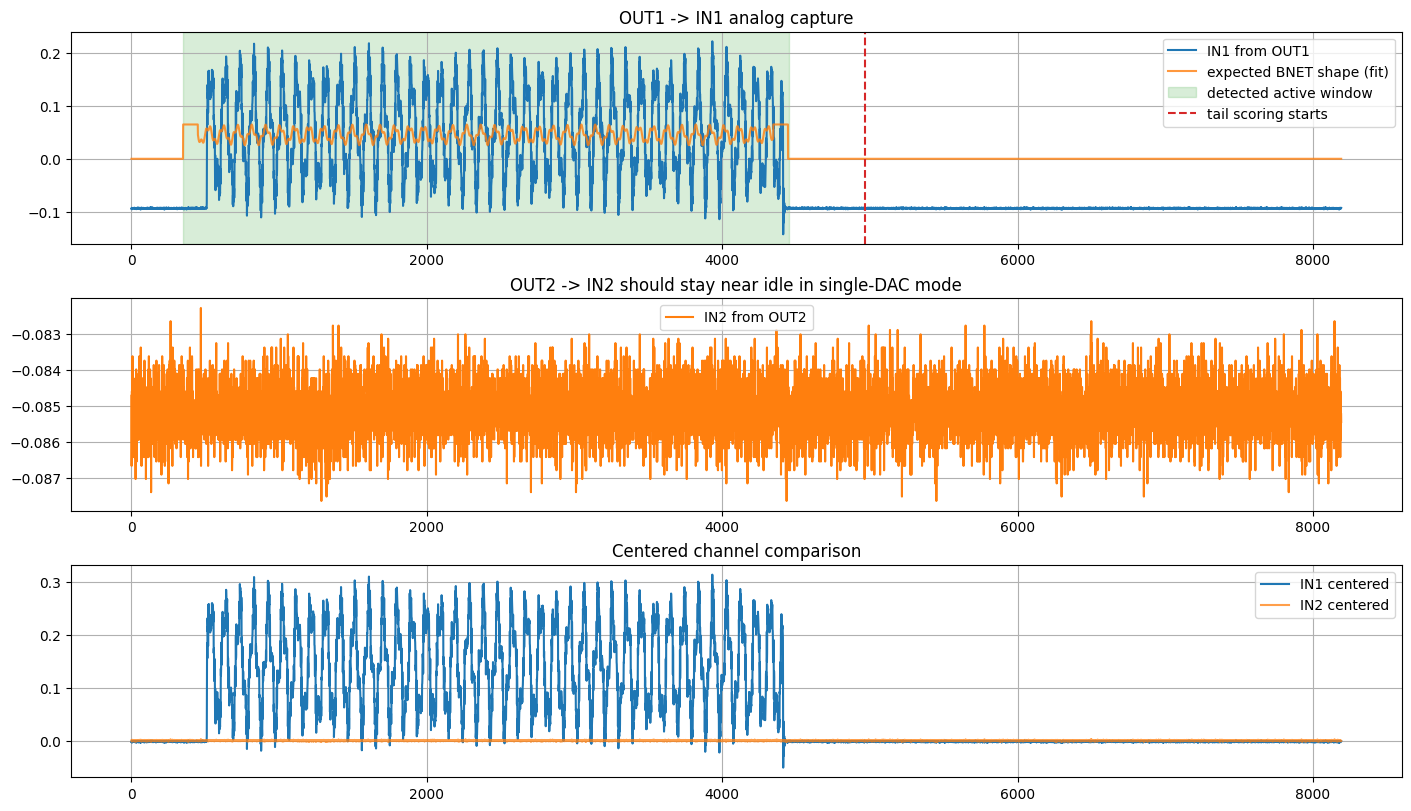

{'status': 2,
 'run': {'status': 2,
  'config': 98,
  'error': 0,
  'capture_count': 2738,
  'capture_status': 0,
  'stream0_status': 4,
  'stream1_status': 4,
  'stream0_rptr': 8192,
  'stream1_rptr': 98304,
  'time0_total': 84046,
  'time1_weight_load': 73726,
  'time2_input_load': 6142,
  'time3_output': 4107,
  'time4_input_load_detail': 6142,
  'time5_latency': 39,
  'time_total': 84046,
  'time_weight_load': 73726,
  'time_input_load': 6142,
  'time_output': 4107,
  'time_latency': 39},
 'active_start': 350,
 'active_stop': 4454,
 'active_rms': 0.16148897226741482,
 'idle_rms': 0.11937108639967745,
 'tail_rms': 0.0020864622820239826,
 'tail_to_active_ratio': 0.012920153325200077,
 'in2_rms': 0.0007331577504939669,
 'in2_to_active_ratio': 0.004539986478333067,
 'active_to_idle_ratio': 1.3528315535867586,
 'active_detected': False,
 'tail_ok': True,
 'out2_ok': True}

In [88]:
def parse_scpi_ascii_array(text: str) -> np.ndarray:
    stripped = text.strip().strip("{}")
    if not stripped:
        return np.array([], dtype=np.float64)
    return np.array([float(item) for item in stripped.split(",") if item.strip()], dtype=np.float64)

def wait_for_acq_trigger(timeout_s: float = 3.0) -> str:
    deadline = time.time() + timeout_s
    last = ""
    while time.time() < deadline:
        last = query("ACQ:TRig:STAT?")
        if last.upper().startswith("TD"):
            return last
        time.sleep(0.05)
    return last

def wait_for_acq_fill(timeout_s: float = 3.0) -> bool:
    deadline = time.time() + timeout_s
    while time.time() < deadline:
        try:
            if query_int("ACQ:TRig:FILL?") != 0:
                return True
        except Exception:
            pass
        time.sleep(0.05)
    return False

def acq_trigger_source_is_now() -> bool:
    return str(ACQ_TRIGGER_SOURCE).strip().upper() == "NOW"

def start_dual_channel_acquisition(samples: int = ANALOG_CAPTURE_SAMPLES) -> None:
    strict_cmd("ACQ:RST")
    strict_cmd(f"ACQ:DATA:Units {ACQ_DATA_UNITS}")
    strict_cmd("ACQ:DATA:FORMAT ASCII")
    strict_cmd(f"ACQ:DEC {ACQ_DECIMATION}")
    strict_cmd("ACQ:AVG OFF")
    strict_cmd(f"ACQ:TRig:DLY {ACQ_TRIGGER_DELAY_SAMPLES}")
    strict_cmd(f"ACQ:TRig:LEV {ACQ_TRIGGER_LEVEL}")
    strict_cmd("ACQ:START")
    time.sleep(ACQ_ARM_SETTLE_S)
    if acq_trigger_source_is_now():
        print("Acquisition armed for immediate NOW trigger")
    else:
        strict_cmd(f"ACQ:TRig {ACQ_TRIGGER_SOURCE}")
        print(f"Acquisition armed for trigger source {ACQ_TRIGGER_SOURCE}, level={ACQ_TRIGGER_LEVEL}, delay={ACQ_TRIGGER_DELAY_SAMPLES}")

def read_dual_channel_capture(samples: int = ANALOG_READ_SAMPLES, *, force_latest: bool = False) -> tuple[np.ndarray, np.ndarray]:
    captures = []
    mode = "LATEST" if force_latest else str(ACQ_READ_MODE).strip().upper()
    if mode == "TRIG":
        trigger_pos = query_int("ACQ:TPOS?")
        buffer_size = query_int("ACQ:BUF:SIZE?")
        start = (trigger_pos - ACQ_PRE_TRIGGER_SAMPLES) % buffer_size
        samples = min(int(samples), int(buffer_size))
        print(f"Triggered range read: tpos={trigger_pos}, start={start}, samples={samples}, buffer={buffer_size}")
    else:
        start = 0
    old_verbose = globals().get("VERBOSE_SCPI", True)
    globals()["VERBOSE_SCPI"] = False
    try:
        for channel in (1, 2):
            if mode == "TRIG":
                rp.tx_txt(f"ACQ:SOUR{channel}:DATA:Start:N? {start},{samples}")
            else:
                rp.tx_txt(f"ACQ:SOUR{channel}:DATA:LATest:N? {samples}")
            captures.append(parse_scpi_ascii_array(rp.rx_txt()))
    finally:
        globals()["VERBOSE_SCPI"] = old_verbose
    strict_cmd("ACQ:STOP")
    return captures[0], captures[1]

def find_active_window(signal: np.ndarray, expected_len: int = SDF_VECTOR_LEN) -> tuple[int, int, float, float]:
    y = np.asarray(signal, dtype=np.float64)
    baseline = np.median(y[:min(1024, y.size)])
    centered = y - baseline
    kernel_len = min(expected_len, max(16, centered.size // 2))
    kernel = np.ones(kernel_len) / kernel_len
    energy = np.convolve(centered * centered, kernel, mode="valid")
    start = int(np.argmax(energy)) if energy.size else 0
    stop = min(start + expected_len, y.size)
    active_rms = float(np.sqrt(np.mean(centered[start:stop] ** 2))) if stop > start else 0.0
    idle_rms = float(np.sqrt(np.mean(centered[:min(1024, y.size)] ** 2))) if y.size else 0.0
    return start, stop, active_rms, idle_rms

def split_bnet_codes_to_dac_samples(expected_codes: np.ndarray) -> np.ndarray:
    raw_u14 = np.asarray(expected_codes, dtype=np.int64) & 0x3fff
    fields = np.empty(raw_u14.size * 2, dtype=np.int64)
    fields[0::2] = raw_u14 >> 7
    fields[1::2] = raw_u14 & 0x7f
    dac_u14 = fields << 7
    return np.where(dac_u14 & 0x2000, dac_u14 - 0x4000, dac_u14).astype(np.int16)

def analog_expected_from_codes(expected_codes: np.ndarray) -> np.ndarray:
    # The exact volts/code gain depends on jumper range and analog calibration.
    # Normalize shape here; amplitude is fitted against IN1 in the plot below.
    # Split output followed by combined IN1 reconstructs the original 4096 words.
    if BNET_DAC_SPLIT_OUTPUT and ACQ_BIT_COMBINE:
        return np.asarray(expected_codes, dtype=np.float64)
    dac_codes = split_bnet_codes_to_dac_samples(expected_codes) if BNET_DAC_SPLIT_OUTPUT else expected_codes
    values = np.asarray(dac_codes, dtype=np.float64)
    if ACQ_DECIMATION > 1:
        usable = (values.size // ACQ_DECIMATION) * ACQ_DECIMATION
        if usable > 0:
            values = values[:usable].reshape(-1, ACQ_DECIMATION).mean(axis=1)
    return values

def fit_expected_to_signal(signal: np.ndarray, expected_shape: np.ndarray, start: int) -> np.ndarray:
    fitted = np.zeros_like(signal, dtype=np.float64)
    n = min(expected_shape.size, signal.size - start)
    if n <= 0:
        return fitted
    y = signal[start:start+n].astype(np.float64)
    x = expected_shape[:n].astype(np.float64)
    x0 = x - np.mean(x)
    y0 = y - np.mean(y)
    denom = float(np.dot(x0, x0))
    gain = 0.0 if denom == 0 else float(np.dot(x0, y0) / denom)
    offset = float(np.mean(y) - gain * np.mean(x))
    fitted[start:start+n] = gain * x + offset
    return fitted

def run_analog_loopback_drain_test() -> dict[str, object]:
    setup = configure_sdf_run(sdf_input, sdf_weights, cold=True)
    start_dual_channel_acquisition(ANALOG_CAPTURE_SAMPLES)
    if acq_trigger_source_is_now():
        cmd("ACQ:TRig NOW")
    cmd("BNET:START")
    trigger_ok = True
    if not acq_trigger_source_is_now():
        trigger_state = wait_for_acq_trigger(ACQ_TRIGGER_WAIT_TIMEOUT_S)
        trigger_ok = trigger_state.upper().startswith("TD")
        print("Trigger state:", trigger_state)
    fill_ok = wait_for_acq_fill(ACQ_TRIGGER_FILL_TIMEOUT_S) if trigger_ok else False
    print("Trigger fill:", fill_ok)
    time.sleep(0.002)
    in1, in2 = read_dual_channel_capture(ANALOG_READ_SAMPLES, force_latest=not fill_ok)
    status = wait_for_bnet_done(timeout_s=30.0)
    run = snapshot("Analog loopback drain check BNET run")

    dac_samples_per_result = 2 if BNET_DAC_SPLIT_OUTPUT else 1
    analog_burst_samples = max(16, setup["vector_len"] * dac_samples_per_result // ACQ_DECIMATION + 8)
    start, stop, active_rms, idle_rms = find_active_window(in1, analog_burst_samples)
    expected_analog = analog_expected_from_codes(sdf_reference)
    fitted_expected = fit_expected_to_signal(in1, expected_analog, start)
    tail_start = min(stop + ANALOG_TAIL_GUARD_SAMPLES, in1.size)
    tail = in1[tail_start:]
    tail_centered = tail - np.median(in1[:min(1024, in1.size)]) if tail.size else tail
    tail_rms = float(np.sqrt(np.mean(tail_centered ** 2))) if tail_centered.size else 0.0
    in2_centered = in2 - np.median(in2[:min(1024, in2.size)]) if in2.size else in2
    in2_rms = float(np.sqrt(np.mean(in2_centered ** 2))) if in2_centered.size else 0.0

    drain_ratio = tail_rms / active_rms if active_rms > 0 else float("inf")
    out2_ratio = in2_rms / active_rms if active_rms > 0 else float("inf")
    active_to_idle_ratio = active_rms / idle_rms if idle_rms > 0 else float("inf")
    active_detected = (active_rms >= ANALOG_MIN_ACTIVE_RMS_V) and (active_to_idle_ratio >= ANALOG_MIN_ACTIVE_TO_IDLE_RATIO)

    print(f"Analog active window IN1: start={start}, stop={stop}, active_rms={active_rms:.6f} V, idle_rms={idle_rms:.6f} V, active/idle={active_to_idle_ratio:.2f}x")
    print(f"Analog tail after guard : start={tail_start}, tail_rms={tail_rms:.6f} V, ratio={drain_ratio:.4f}")
    print(f"Analog IN2 whole capture: rms={in2_rms:.6f} V, ratio={out2_ratio:.4f}")
    if not active_detected:
        print("Analog burst was not detected clearly; drain/out2 ratios are noise-dominated and not scored.")

    global analog_loopback_waveforms
    analog_loopback_waveforms = {
        "in1": in1,
        "in2": in2,
        "expected_analog": expected_analog,
        "fitted_expected": fitted_expected,
        "active_start": start,
        "active_stop": stop,
        "tail_start": tail_start,
        "acq_decimation": ACQ_DECIMATION,
        "trigger_source": ACQ_TRIGGER_SOURCE,
        "trigger_delay_samples": ACQ_TRIGGER_DELAY_SAMPLES,
    }

    fig, axes = plt.subplots(3, 1, figsize=(14, 8), constrained_layout=True)
    x = np.arange(in1.size)
    axes[0].plot(x, in1, label="IN1 from OUT1")
    axes[0].plot(x, fitted_expected[:in1.size], label="expected BNET shape (fit)", alpha=0.8)
    axes[0].axvspan(start, stop, color="C2", alpha=0.18, label="detected active window")
    axes[0].axvline(tail_start, color="C3", linestyle="--", label="tail scoring starts")
    axes[0].set_title("OUT1 -> IN1 analog capture")
    axes[0].grid(True)
    axes[0].legend()

    axes[1].plot(np.arange(in2.size), in2, color="C1", label="IN2 from OUT2")
    axes[1].set_title("OUT2 -> IN2 should stay near idle in single-DAC mode")
    axes[1].grid(True)
    axes[1].legend()

    n = min(in1.size, in2.size)
    axes[2].plot(np.arange(n), in1[:n] - np.median(in1[:min(1024, n)]), label="IN1 centered")
    axes[2].plot(np.arange(n), in2[:n] - np.median(in2[:min(1024, n)]), label="IN2 centered", alpha=0.75)
    axes[2].set_title("Centered channel comparison")
    axes[2].grid(True)
    axes[2].legend()
    plt.show()

    result = {
        "status": int(status),
        "run": run,
        "active_start": start,
        "active_stop": stop,
        "active_rms": active_rms,
        "idle_rms": idle_rms,
        "tail_rms": tail_rms,
        "tail_to_active_ratio": drain_ratio,
        "in2_rms": in2_rms,
        "in2_to_active_ratio": out2_ratio,
        "active_to_idle_ratio": active_to_idle_ratio,
        "active_detected": bool(active_detected),
        "tail_ok": bool(drain_ratio < ANALOG_DRAIN_RMS_RATIO_LIMIT),
        "out2_ok": bool(out2_ratio < ANALOG_OUT2_RMS_RATIO_LIMIT),
    }
    if result["active_detected"]:
        warn_check(result["tail_ok"], "Analog tail is below drain threshold", result)
        warn_check(result["out2_ok"], "Analog OUT2/IN2 is below quiet threshold", result)
    return result

if RUN_ANALOG_LOOPBACK_DRAIN_TEST:
    analog_loopback_drain_result = run_analog_loopback_drain_test()
else:
    analog_loopback_drain_result = {"skipped": True}
    print("Analog loopback drain test skipped")

analog_loopback_drain_result

## Analog Loopback Quality Analysis

This block compares the latest OUT1-to-IN1 analog capture with the expected BNET scalar result. The analog path has unknown gain/offset, so the expected digital waveform is fitted to IN1 before scoring shape error.

Analog BNET quality
  start              = 416
  stop               = 4512
  samples            = 4096
  gain_v_per_code    = 0.0002753425440960867
  offset_v           = -0.08956697332464636
  correlation        = 0.9727714009962829
  signal_rms_v       = 0.08411681987352732
  error_rms_v        = 0.01949547742537216
  normalized_rmse    = 0.2317666960625035
  peak_abs_error_v   = 0.22958197332464636
  in2_rms_v          = 0.000733158


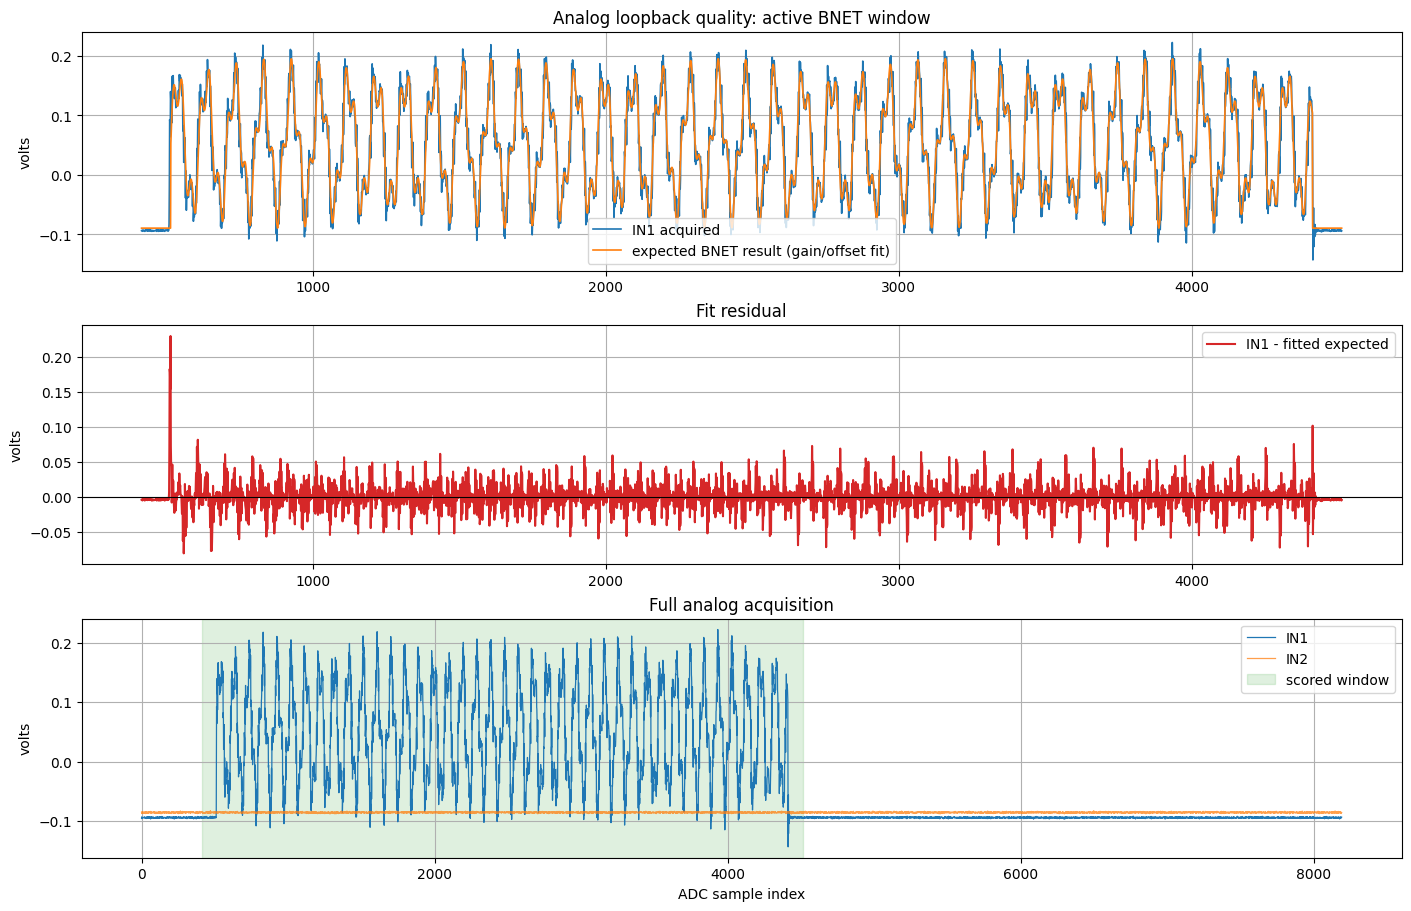

{'valid': True,
 'start': 416,
 'stop': 4512,
 'samples': 4096,
 'gain_v_per_code': 0.0002753425440960867,
 'offset_v': -0.08956697332464636,
 'correlation': 0.9727714009962829,
 'signal_rms_v': 0.08411681987352732,
 'error_rms_v': 0.01949547742537216,
 'normalized_rmse': 0.2317666960625035,
 'peak_abs_error_v': 0.22958197332464636}

In [89]:
def fit_expected_segment(signal: np.ndarray, expected: np.ndarray, start: int) -> dict[str, object]:
    signal = np.asarray(signal, dtype=np.float64)
    expected = np.asarray(expected, dtype=np.float64)
    n = min(expected.size, signal.size - start)
    if start < 0 or n <= 8:
        return {"valid": False, "correlation": -2.0}
    y = signal[start:start+n]
    x = expected[:n]
    x0 = x - np.mean(x)
    y0 = y - np.mean(y)
    denom = float(np.dot(x0, x0))
    gain = 0.0 if denom == 0 else float(np.dot(x0, y0) / denom)
    offset = float(np.mean(y) - gain * np.mean(x))
    fitted = gain * x + offset
    err = y - fitted
    signal_rms = float(np.sqrt(np.mean((y - np.mean(y)) ** 2)))
    error_rms = float(np.sqrt(np.mean(err ** 2)))
    corr = normalized_correlation(y, fitted)
    return {
        "valid": True,
        "start": int(start),
        "stop": int(start + n),
        "samples": int(n),
        "gain_v_per_code": gain,
        "offset_v": offset,
        "correlation": corr,
        "signal_rms_v": signal_rms,
        "error_rms_v": error_rms,
        "normalized_rmse": error_rms / signal_rms if signal_rms > 0 else float("inf"),
        "peak_abs_error_v": float(np.max(np.abs(err))) if err.size else 0.0,
        "fitted": fitted,
        "error": err,
    }

def evaluate_analog_loopback_quality(search_radius: int = 256) -> dict[str, object]:
    if "analog_loopback_waveforms" not in globals():
        raise RuntimeError("Run the analog loopback acquisition cell first.")
    wave = analog_loopback_waveforms
    in1 = np.asarray(wave["in1"], dtype=np.float64)
    in2 = np.asarray(wave["in2"], dtype=np.float64)
    expected = np.asarray(wave["expected_analog"], dtype=np.float64)
    nominal_start = int(wave["active_start"])

    candidates = range(max(0, nominal_start - search_radius), min(in1.size, nominal_start + search_radius + 1))
    fits = [fit_expected_segment(in1, expected, start) for start in candidates]
    best = max((fit for fit in fits if fit.get("valid")), key=lambda fit: fit["correlation"])

    start = best["start"]
    stop = best["stop"]
    x = np.arange(start, stop)
    y = in1[start:stop]
    fitted = best["fitted"]
    err = best["error"]
    plot_units = "signed ADC code" if ACQ_BIT_COMBINE else "volts"

    print("Analog BNET quality")
    for key in ("start", "stop", "samples", "gain_v_per_code", "offset_v", "correlation", "signal_rms_v", "error_rms_v", "normalized_rmse", "peak_abs_error_v"):
        print(f"  {key:18s} = {best[key]}")
    print(f"  in2_rms_v          = {float(np.sqrt(np.mean((in2 - np.median(in2)) ** 2))):.6g}")

    fig, axes = plt.subplots(3, 1, figsize=(14, 9), constrained_layout=True)
    axes[0].plot(x, y, label="IN1 acquired", linewidth=1.2)
    axes[0].plot(x, fitted, label="expected BNET result (gain/offset fit)", linewidth=1.2)
    axes[0].set_title("Analog loopback quality: active BNET window")
    axes[0].set_ylabel(plot_units)
    axes[0].grid(True)
    axes[0].legend()

    axes[1].plot(x, err, label="IN1 - fitted expected", color="C3")
    axes[1].axhline(0.0, color="k", linewidth=0.8)
    axes[1].set_title("Fit residual")
    axes[1].set_ylabel(plot_units)
    axes[1].grid(True)
    axes[1].legend()

    full_x = np.arange(in1.size)
    axes[2].plot(full_x, in1, label="IN1", linewidth=0.9)
    axes[2].plot(np.arange(in2.size), in2, label="IN2", linewidth=0.9, alpha=0.75)
    axes[2].axvspan(start, stop, color="C2", alpha=0.15, label="scored window")
    axes[2].set_title("Full analog acquisition")
    axes[2].set_xlabel("ADC sample index")
    axes[2].set_ylabel(plot_units)
    axes[2].grid(True)
    axes[2].legend()
    plt.show()

    return {key: value for key, value in best.items() if key not in ("fitted", "error")}

analog_quality_result = evaluate_analog_loopback_quality()
analog_quality_result

## Cold Static SDF Run with Digital Readback

This loads both samples and weights, starts BNET, reads the digital capture RAM, and requires an exact integer match against the fixed-point reference.

>> BNET:RST
>> BNET:DDR:START?
<< 16777216
>> BNET:DDR:SIZE?
<< 33554432
>> BNET:DDR:SLOT0:RELEASE
>> BNET:DDR:SLOT1:RELEASE
>> BNET:DDR:SLOT0:RESERVE 16777216,8192
>> BNET:DDR:SLOT0:STREAM0:BUF0
>> BNET:STREAM0:BASE0?
<< 16777216
>> BNET:STREAM0:LENGTH?
<< 8192
OK: STREAM0 BASE0 matches sample slot
OK: STREAM0 length matches sample bytes
>> BNET:DDR:SLOT1:RESERVE 16785408,98304
>> BNET:DDR:SLOT1:STREAM1:BUF0
>> BNET:STREAM1:BASE0?
<< 16785408
>> BNET:STREAM1:LENGTH?
<< 98304
OK: STREAM1 BASE0 matches weight slot
OK: STREAM1 length matches weight bytes
>> BNET:VLEN 4096
>> BNET:STREAM0:FORMAT 0
>> BNET:STREAM1:FORMAT 0
>> BNET:STREAM0:ENABLE 1
>> BNET:STREAM1:ENABLE 1
>> BNET:STREAM0:COMMIT0
>> BNET:STREAM1:COMMIT0
>> BNET:MODE DDR
>> BNET:PIPELINE 1
>> BNET:DAC:SINGLE 1
>> BNET:WEIGHT:REUSE 0
>> BNET:CONFIG?
<< 98
OK: BNET config is expected 0x62 before run
>> BNET:STREAM1:RPTR?
<< 0
>> BNET:START
>> BNET:STATUS?
<< 2
Cold static SDF 4096, single-DAC serialized output, digital capture

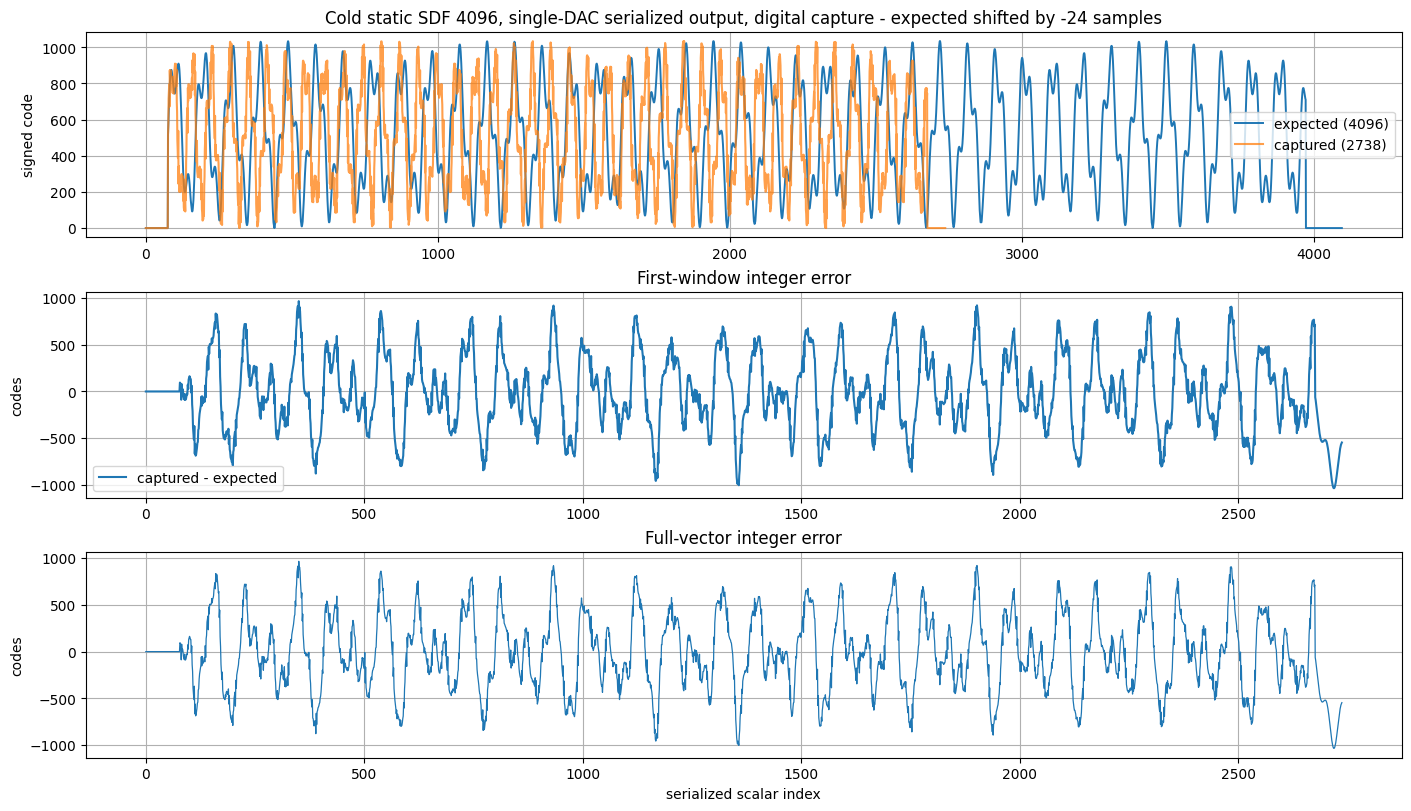

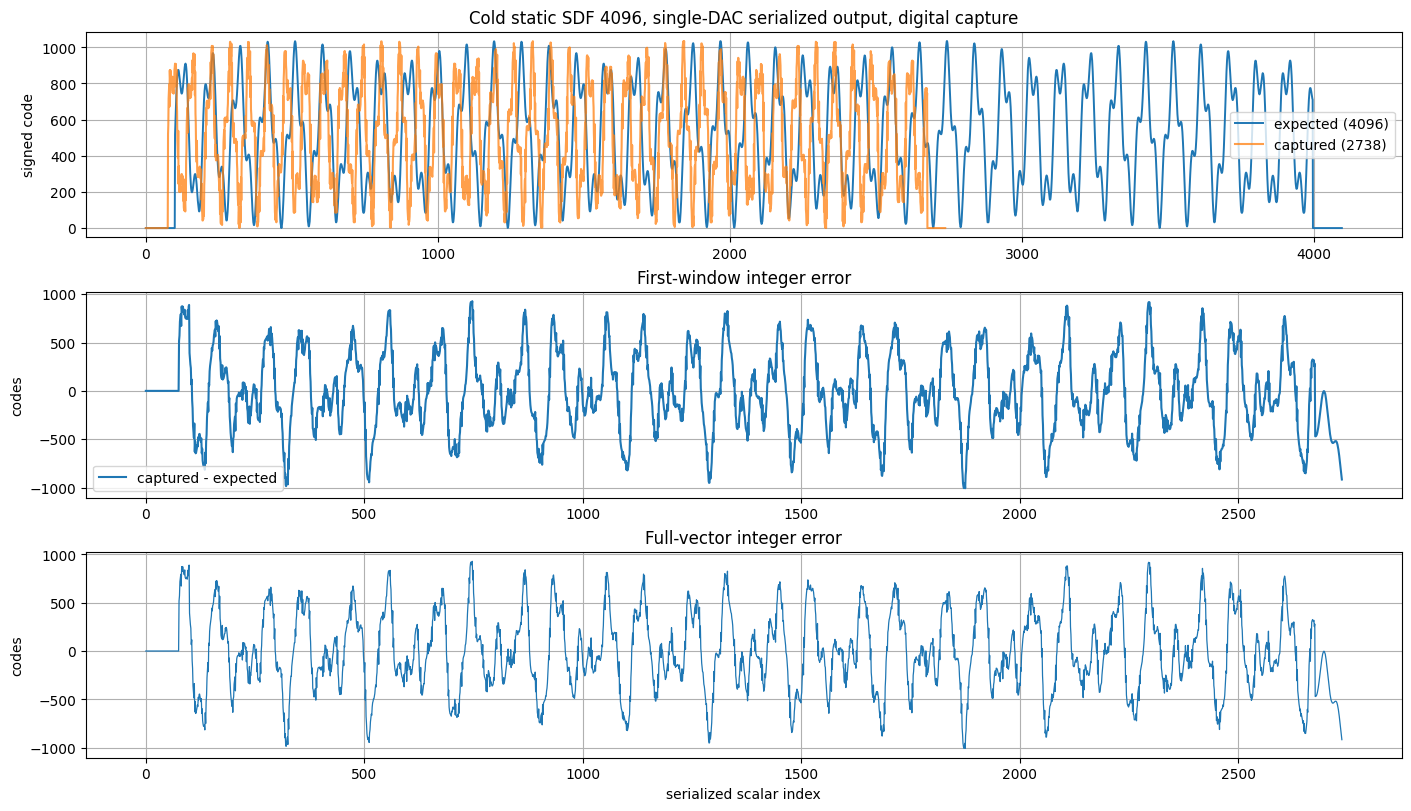

Cold timing: total=84046 cycles (672.37 us), weight_load=73726 cycles, input_load=6142 cycles, latency=39 cycles, output=4107 cycles


{'scored_len': 2738,
 'exact_match': False,
 'mismatch_count': 2656,
 'max_abs_error': 1007,
 'correlation': 0.07398068880480782,
 'first_mismatch': 76}

In [90]:
if RUN_EXACT_DIGITAL_CAPTURE:
    cold_result = run_sdf_capture_test(
        "Cold static SDF 4096, single-DAC serialized output, digital capture",
        sdf_input,
        sdf_reference,
        cold=True,
        weight_i16=sdf_weights,
    )

    cold_t = cold_result["run"]
    print(
        f"Cold timing: total={cold_t['time_total']} cycles ({cycles_to_us(cold_t['time_total']):.2f} us), "
        f"weight_load={cold_t['time_weight_load']} cycles, "
        f"input_load={cold_t['time_input_load']} cycles, "
        f"latency={cold_t['time_latency']} cycles, "
        f"output={cold_t['time_output']} cycles"
    )
else:
    cold_result = {"skipped": True, "reason": "RUN_EXACT_DIGITAL_CAPTURE is False"}
    print("Exact digital capture readback skipped until indexed CAPTURE#:DATA? SCPI fix is installed.")

cold_result.get("metrics", cold_result)

## Warm Static SDF Run without Weight Reload

This reuses the static weights already loaded by the cold run. Only stream 0 is re-uploaded and enabled. The stream 1 read pointer should not advance.

>> BNET:DDR:START?
<< 16777216
>> BNET:DDR:SIZE?
<< 33554432
>> BNET:DDR:SLOT0:RELEASE
>> BNET:DDR:SLOT0:RESERVE 16777216,8192
>> BNET:DDR:SLOT0:STREAM0:BUF0
>> BNET:STREAM0:BASE0?
<< 16777216
>> BNET:STREAM0:LENGTH?
<< 8192
OK: STREAM0 BASE0 matches sample slot
OK: STREAM0 length matches sample bytes
>> BNET:VLEN 4096
>> BNET:STREAM0:FORMAT 0
>> BNET:STREAM1:FORMAT 0
>> BNET:STREAM0:ENABLE 1
>> BNET:STREAM1:ENABLE 0
>> BNET:STREAM0:COMMIT0
>> BNET:MODE DDR
>> BNET:PIPELINE 1
>> BNET:DAC:SINGLE 1
>> BNET:WEIGHT:REUSE 0
>> BNET:CONFIG?
<< 98
OK: BNET config is expected 0x62 before run
>> BNET:STREAM1:RPTR?
<< 98304
>> BNET:START
>> BNET:STATUS?
<< 2
Warm static SDF 4096, reused weights, digital capture completed with STATUS=0x2
>> BNET:STATUS?
<< 2
>> BNET:CONFIG?
<< 98
>> BNET:ERROR?
<< 0
>> BNET:CAPTURE:COUNT?
<< 2738
>> BNET:CAPTURE:STATUS?
<< 0
>> BNET:STREAM0:STATUS?
<< 4
>> BNET:STREAM1:STATUS?
<< 0
>> BNET:STREAM0:RPTR?
<< 8192
>> BNET:STREAM1:RPTR?
<< 98304
>> BNET:TIME0?
<< 102

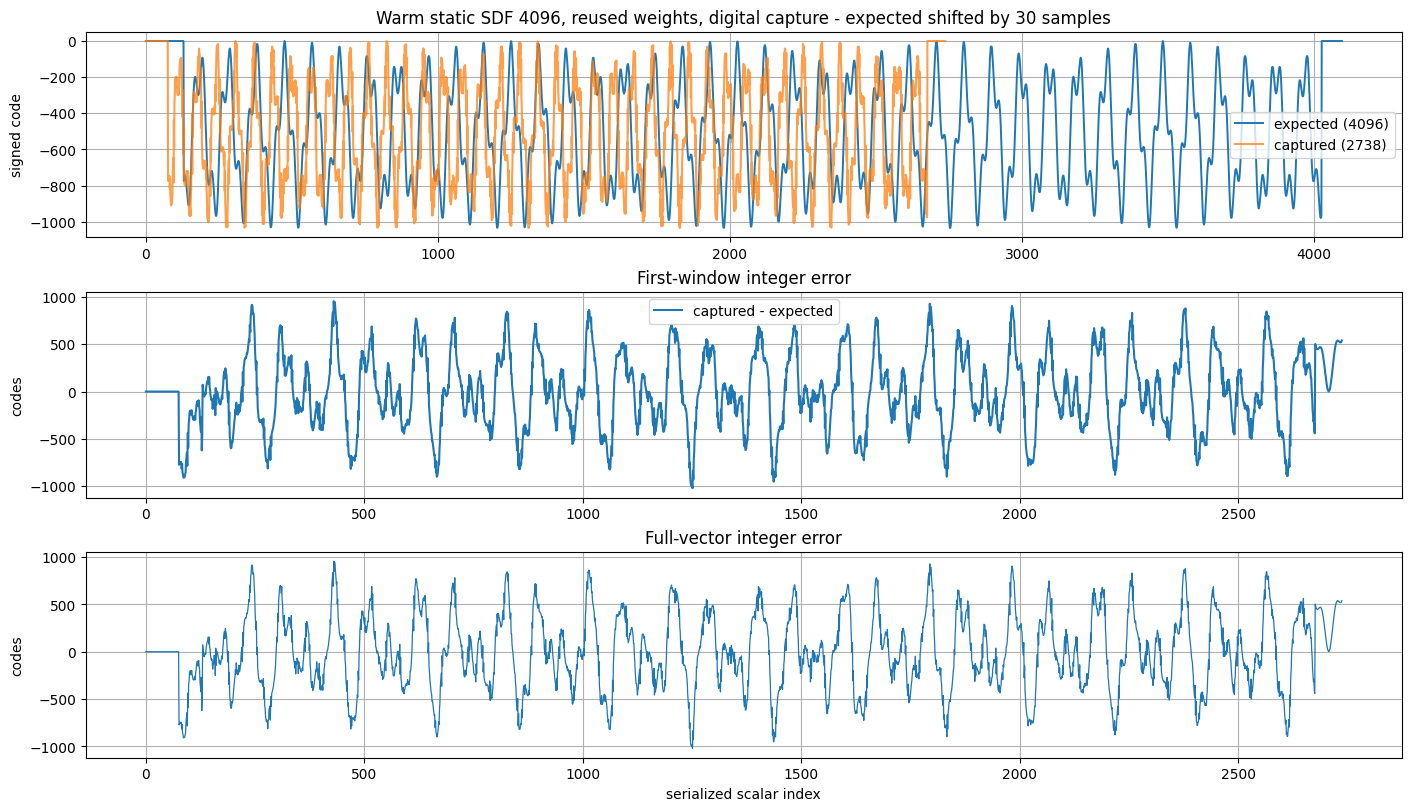

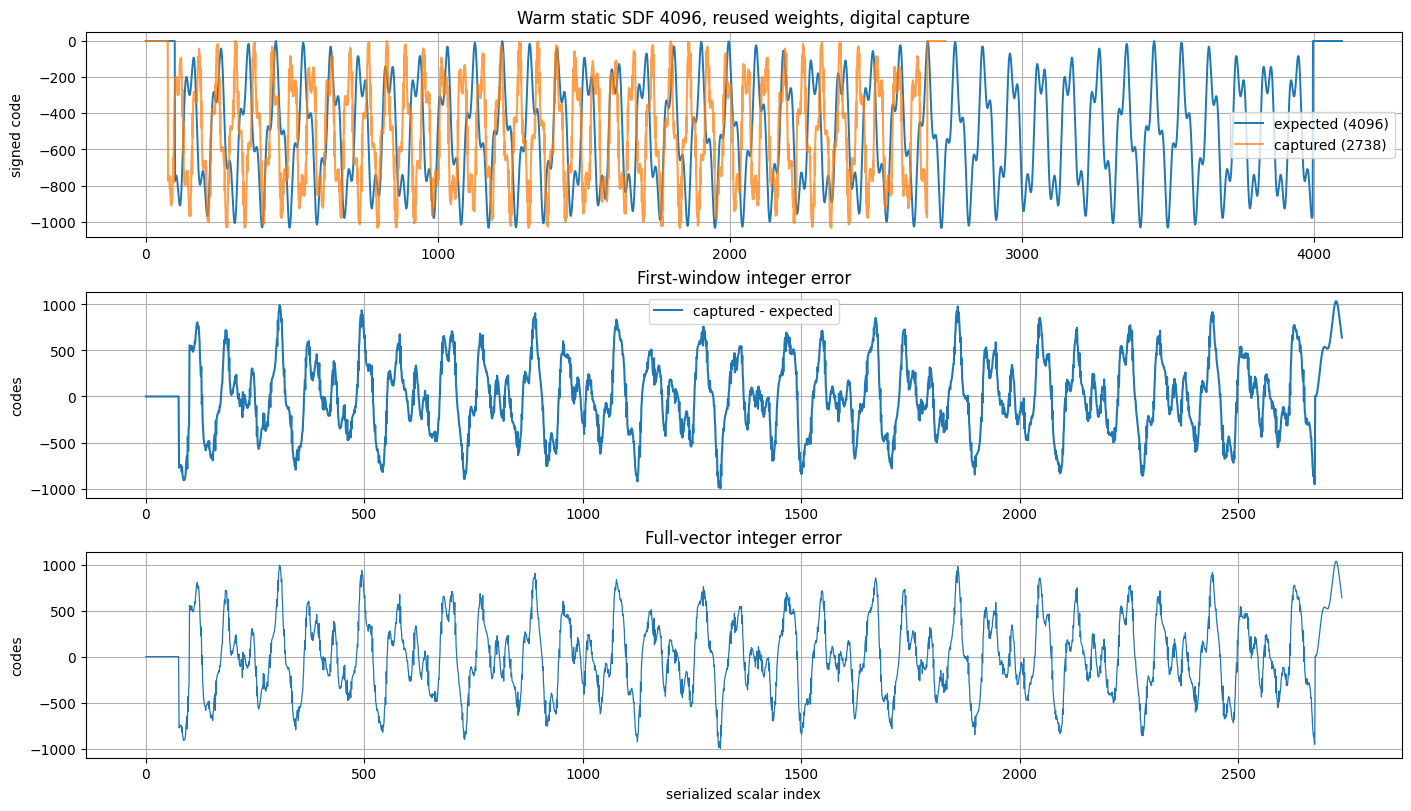

Warm timing: total=10287 cycles (82.30 us), weight_load=73726 cycles, input_load=6142 cycles, latency=39 cycles, output=4107 cycles


{'scored_len': 2738,
 'exact_match': False,
 'mismatch_count': 2659,
 'max_abs_error': 1035,
 'correlation': 0.044830999151669174,
 'first_mismatch': 76}

In [91]:
if RUN_EXACT_DIGITAL_CAPTURE:
    warm_result = run_sdf_capture_test(
        "Warm static SDF 4096, reused weights, digital capture",
        warm_input,
        warm_reference,
        cold=False,
        weight_i16=None,
    )

    warm_t = warm_result["run"]
    print(
        f"Warm timing: total={warm_t['time_total']} cycles ({cycles_to_us(warm_t['time_total']):.2f} us), "
        f"weight_load={warm_t['time_weight_load']} cycles, "
        f"input_load={warm_t['time_input_load']} cycles, "
        f"latency={warm_t['time_latency']} cycles, "
        f"output={warm_t['time_output']} cycles"
    )
else:
    warm_result = {"skipped": True, "reason": "RUN_EXACT_DIGITAL_CAPTURE is False"}
    print("Exact warm digital capture readback skipped until indexed CAPTURE#:DATA? SCPI fix is installed.")

warm_result.get("metrics", warm_result)

## Feature Summary

In [92]:
summary = {
    "safe_cold_total_cycles": safe_cold_result.get("run", {}).get("time_total") if isinstance(safe_cold_result, dict) else None,
    "safe_warm_total_cycles": safe_warm_result.get("run", {}).get("time_total") if isinstance(safe_warm_result, dict) else None,
    "safe_cold_capture_count": safe_cold_result.get("run", {}).get("capture_count") if isinstance(safe_cold_result, dict) else None,
    "safe_warm_capture_count": safe_warm_result.get("run", {}).get("capture_count") if isinstance(safe_warm_result, dict) else None,
    "analog_tail_ok": analog_loopback_drain_result.get("tail_ok") if isinstance(analog_loopback_drain_result, dict) else None,
    "analog_out2_ok": analog_loopback_drain_result.get("out2_ok") if isinstance(analog_loopback_drain_result, dict) else None,
    "cold_exact_match": cold_result.get("metrics", {}).get("exact_match") if isinstance(cold_result, dict) else None,
    "warm_exact_match": warm_result.get("metrics", {}).get("exact_match") if isinstance(warm_result, dict) else None,
}
summary

{'safe_cold_total_cycles': 84046,
 'safe_warm_total_cycles': 10287,
 'safe_cold_capture_count': 2738,
 'safe_warm_capture_count': 2738,
 'analog_tail_ok': True,
 'analog_out2_ok': True,
 'cold_exact_match': False,
 'warm_exact_match': False}